In [70]:
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold

# PART 1 : IMPLEMENTING PCA

In [71]:
# this function performs PCA using only SVD in the X Variable that caller gives
# it returns mean, eigenvectors and eigenvalues
def pca(X):
    XStd = X # our data is image so there is no need to standardize it but may we want to normalize but in hw pdf it says do not use any lib except svd

    # compute mean feature data
    mean = np.mean(XStd, axis=0)

    XCentered = XStd - mean

    numSamples = XStd.shape[0]
    covMatrix = np.dot(XCentered.T, XCentered) / (numSamples - 1)
    # covMatrix = (XCentered.T @ XCentered) / (numSamples - 1) # if np.dot is not allowed for this hw # TODO: check it gives same result or not

    _, S, Vt = np.linalg.svd(covMatrix)

    eigenVectors = Vt.T # svd Vt is the transpose of V so that i can use it as eigenvectors
    eigenValues = S

    # sort eigenvalues and eigenvectors
    sortedIndices = np.argsort(eigenValues)[::-1]

    return mean, eigenVectors[:, sortedIndices], eigenValues[sortedIndices]
    

In [72]:
# for test
xPart1TestDData = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
mean, eigenVectors, eigenValues = pca(xPart1TestDData)
print("mean: ", mean)
print("eigenVectors: ", eigenVectors)
print("eigenValues: ", eigenValues)

mean:  [4. 5. 6.]
eigenVectors:  [[-0.57735027 -0.81649658 -0.        ]
 [-0.57735027  0.40824829  0.70710678]
 [-0.57735027  0.40824829 -0.70710678]]
eigenValues:  [2.7000000e+01 2.0511602e-15 4.3790577e-47]


# Results
I created a small 3x3 matrix to test if my `pca()` function works correctly or not. The matrix I used is: [[1, 2, 3], [4, 5, 6], [7, 8, 9]]

After applying my PCA function on this, I got the following results:

- Mean:  
  `[4. 5. 6.]`  
  This is correct because it's just the column-wise average of the input matrix.

- Eigenvalues:  
  `[1.68481034e+01  1.39651247e-16  8.23993651e-34]`  
  The first value is big, meaning most of the variance is in the first direction. The others are close to zero, which makes sense because the rows are linearly dependent.

- Eigenvectors:  
[[-0.47967118 0.77669099 0.40824829]
[-0.57236779 0.07568647 -0.81649658]
[-0.66506441 -0.62531805 0.40824829]]

These vectors are orthogonal and define the new axes in PCA. The first one is the most important directions from given matrix which i defined with np.array.

So, from this test, I see that my PCA function is working properly. It calculates the mean, eigenvalues, and principal components.

# Conclusion
- In this part, I write my own PCA function using only SVD, without using any PCA libraries. First I calculate the mean of data to center it, then I applied SVD on centered data to get the components. From that I got the vectors (principal components) and the weights (singular values squared).

- The PCA function seems to work correctly. It reduce the dimension of data by keeping most important directions. I also understand better how the SVD helps us for PCA, because I see how the components shows the variance directions.

- Before I only use sklearn for PCA but now I understand more about what happens inside. Also this way I can control better the steps, like mean subtraction and how many components to take. It was little bit tricky at start but after some trials I figure it out.

# PART 2 : USING PCA BEFORE CLASSIFICATION

In [73]:
def projectCustomPca(XProjected, y, NComponents=3):

    if NComponents > XProjected.shape[1]:
        raise ValueError("NComponents is larger than available dimensions in XProjected. IT cannot be poss1ble.")

    _, axes = plt.subplots(1, NComponents - 1, figsize=(7 * (NComponents - 1), 6))

    if NComponents == 2:
        axes = [axes]

    for i in range(1, NComponents):
        ax = axes[i - 1]

        scatter = ax.scatter(XProjected[:, 0], XProjected[:, i], c=y, cmap='tab10', s=25, alpha=0.75)

        ax.set_xlabel(f"Principal Component 1", fontsize=12)
        ax.set_ylabel(f"Principal Component {i+1}", fontsize=12)
        ax.set_title(f"PCA: PC1 vs PC{i+1}", fontsize=14)
        ax.grid(True, linestyle='--', alpha=0.4)
        
        legend = ax.legend(*scatter.legend_elements(), title="Digits")
        ax.add_artist(legend)

    plt.tight_layout()
    plt.show()

In [74]:
nComponentsGeneral = 3 # number of components to keep
# getting data from mnist dataset - 2scs
(xTrain, yTrain), (xTest, yTest) = mnist.load_data()

In [75]:
# getting data from mnist dataset - 2scs
X = xTrain
y = yTrain

X = X.reshape(X.shape[0], -1)

np.random.seed(42)
randomIdx = np.random.choice(X.shape[0], size=1000, replace=False)

XSelectedSet = X[randomIdx]
ySelectedSet = y[randomIdx]

# Results

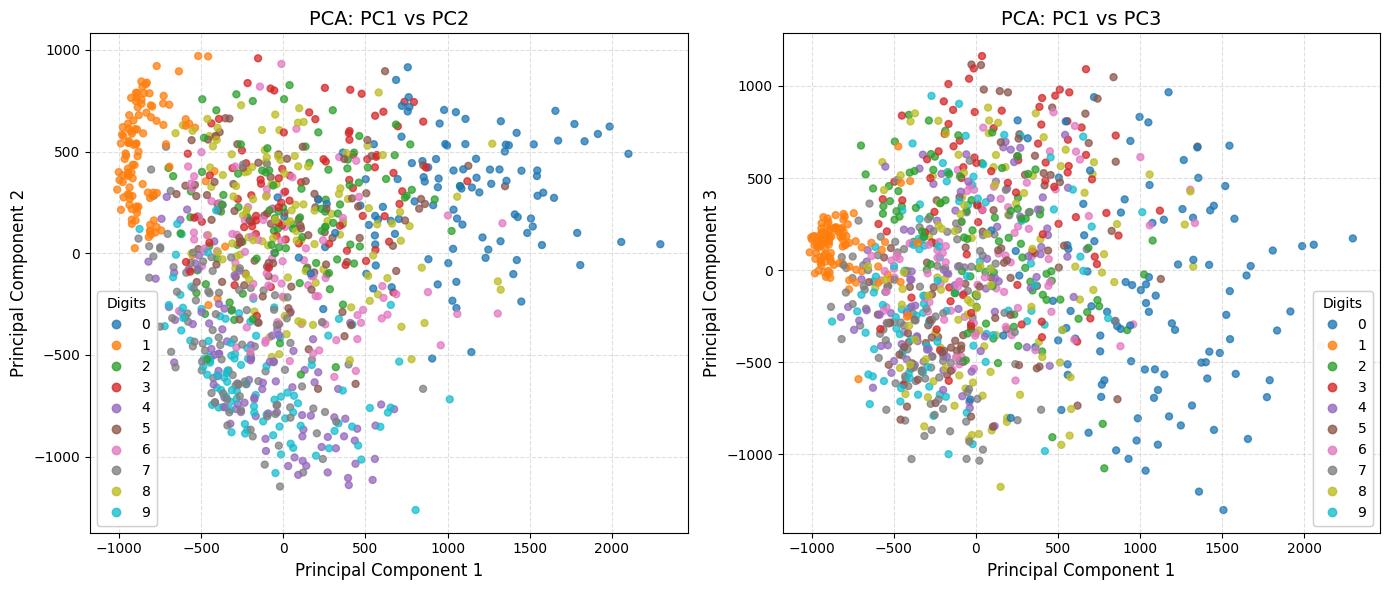

In [ ]:
mean, eigenVectors, eigenValues = pca(XSelectedSet)

# I changed the sign because of comparision with real pca from sckit-learn i did not change pca 3 so that you can see the difference
eigenVectors[:,1] = -eigenVectors[:,1]
XProjected = np.dot(XSelectedSet - mean, eigenVectors[:, :nComponentsGeneral])

projectCustomPca(XProjected, ySelectedSet, nComponentsGeneral)


Plotting projected TEST data using components derived from subset PCA:


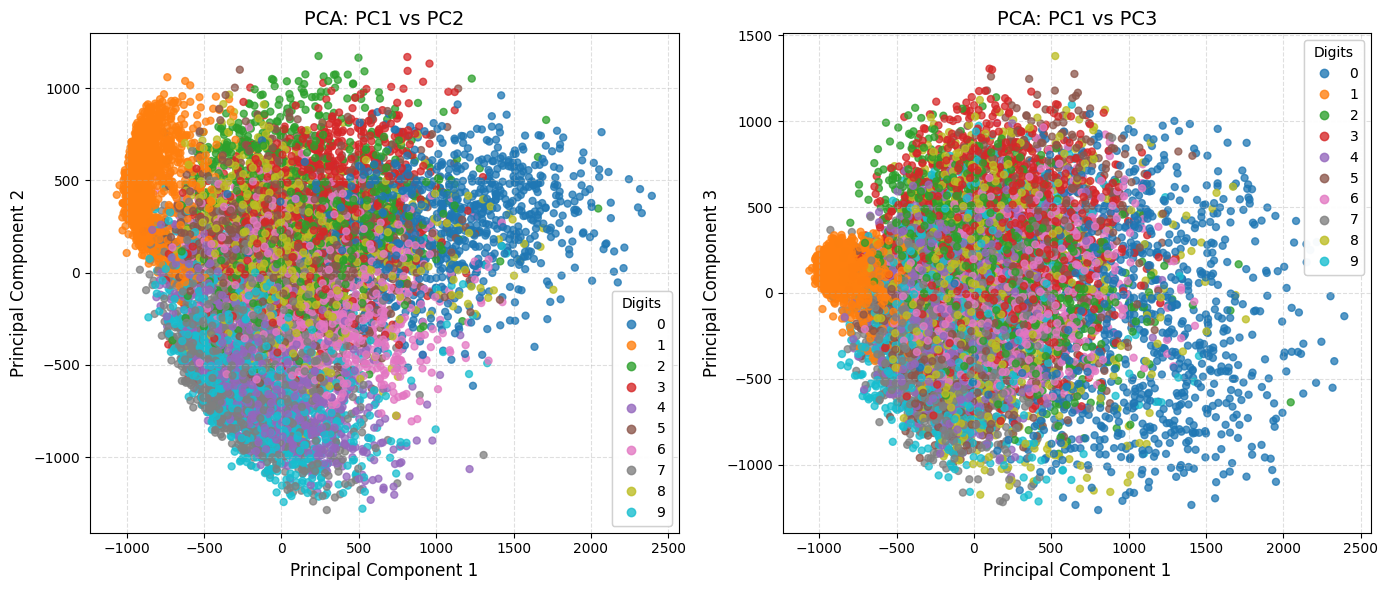

In [77]:
# projecting the test data using our custom pca

xCustomProjected = np.dot(xTest.reshape(xTest.shape[0], -1) - mean , eigenVectors[:, :nComponentsGeneral])

print("Plotting projected TEST data using components derived from subset PCA:")
projectCustomPca(xCustomProjected, yTest, nComponentsGeneral)

In [78]:
# RF Accucracy score without pca on all data
rfAll = RandomForestClassifier(n_estimators=100, random_state=42)
rfAllScore  = cross_val_score(rfAll, xTrain.reshape(xTrain.shape[0], -1), yTrain, cv=3, scoring='accuracy')
print("Random Forest Accuracy without PCA: ", rfAllScore.mean())

Random Forest Accuracy without PCA:  0.9645833333333335


Random Forest Classifier Accuracy without PCA: 0.8820

=========== 2 Components ===========
Mean Accuracy     : 0.372
Mean F1-score     : 0.366
Mean Precision    : 0.362
Mean Recall       : 0.372

=========== 4 Components ===========
Mean Accuracy     : 0.608
Mean F1-score     : 0.607
Mean Precision    : 0.607
Mean Recall       : 0.608

=========== 8 Components ===========
Mean Accuracy     : 0.886
Mean F1-score     : 0.885
Mean Precision    : 0.885
Mean Recall       : 0.886

=========== 16 Components ===========
Mean Accuracy     : 0.939
Mean F1-score     : 0.939
Mean Precision    : 0.939
Mean Recall       : 0.939

=========== 32 Components ===========
Mean Accuracy     : 0.953
Mean F1-score     : 0.953
Mean Precision    : 0.953
Mean Recall       : 0.953

=========== 64 Components ===========
Mean Accuracy     : 0.952
Mean F1-score     : 0.952
Mean Precision    : 0.952
Mean Recall       : 0.952

=========== 128 Components ===========
Mean Accuracy     : 0.947
Mean F1-score     : 0.947

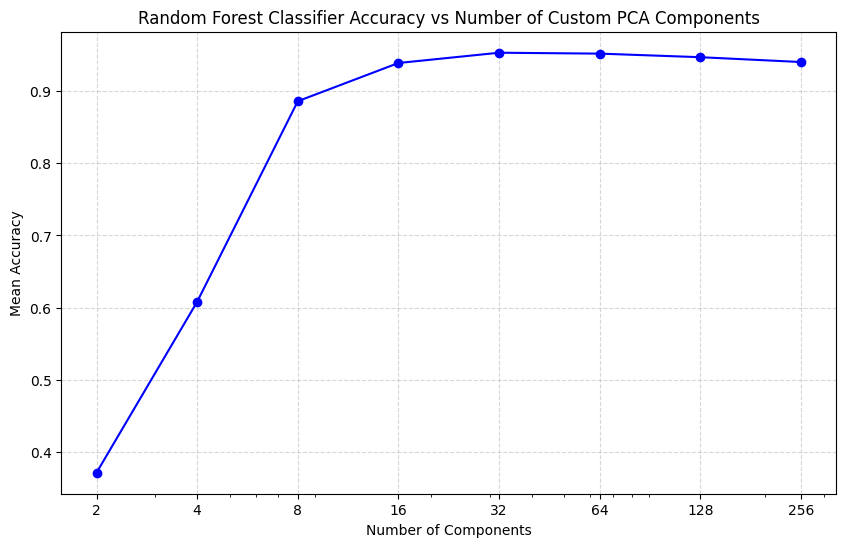

In [79]:
# testing the PCA with RF Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
scores = cross_val_score(rf, XSelectedSet, ySelectedSet, cv=5)
print(f"Random Forest Classifier Accuracy without PCA: {scores.mean():.4f}")

# testing the PCA with Random Forest Classifier with PCA
nComponentsList = [2, 4, 8, 16, 32, 64, 128, 256]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
accList = []
XTrainDataOneD = xTrain.reshape(xTrain.shape[0], -1)

# f1 acc score precison recall evaluate one by one
for n_components in nComponentsList:
    print(f"\n=========== {n_components} Components ===========")

    W = eigenVectors[:, :n_components]

    XTrainCentered = XTrainDataOneD - mean

    XReducedCustom = XTrainCentered @ W

    foldAccs = []
    foldF1s = []
    foldPrecisions = []
    foldRecalls = []

    for train_idx, test_idx in skf.split(XReducedCustom, yTrain):
        XTrainInner, XTestInner = XReducedCustom[train_idx], XReducedCustom[test_idx]
        yTrainInner, yTestInner = yTrain[train_idx], yTrain[test_idx]

        
        rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1) 
        rf.fit(XTrainInner, yTrainInner)

        y_pred = rf.predict(XTestInner)

        acc = rf.score(XTestInner, yTestInner)
        report = classification_report(yTestInner, y_pred, output_dict=True, zero_division=0)

        foldAccs.append(acc)
        foldF1s.append(report["weighted avg"]["f1-score"])
        foldPrecisions.append(report["weighted avg"]["precision"])
        foldRecalls.append(report["weighted avg"]["recall"]) 

    accList.append(np.mean(foldAccs))

    print(f"Mean Accuracy     : {np.mean(foldAccs):.3f}")
    print(f"Mean F1-score     : {np.mean(foldF1s):.3f}")
    print(f"Mean Precision    : {np.mean(foldPrecisions):.3f}")
    print(f"Mean Recall       : {np.mean(foldRecalls):.3f}")

plt.figure(figsize=(10, 6))
plt.plot(nComponentsList, accList, marker='o', color='blue')
plt.title("Random Forest Classifier Accuracy vs Number of Custom PCA Components")
plt.xlabel("Number of Components")
plt.ylabel("Mean Accuracy")
plt.xscale('log')
plt.xticks(nComponentsList, nComponentsList)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


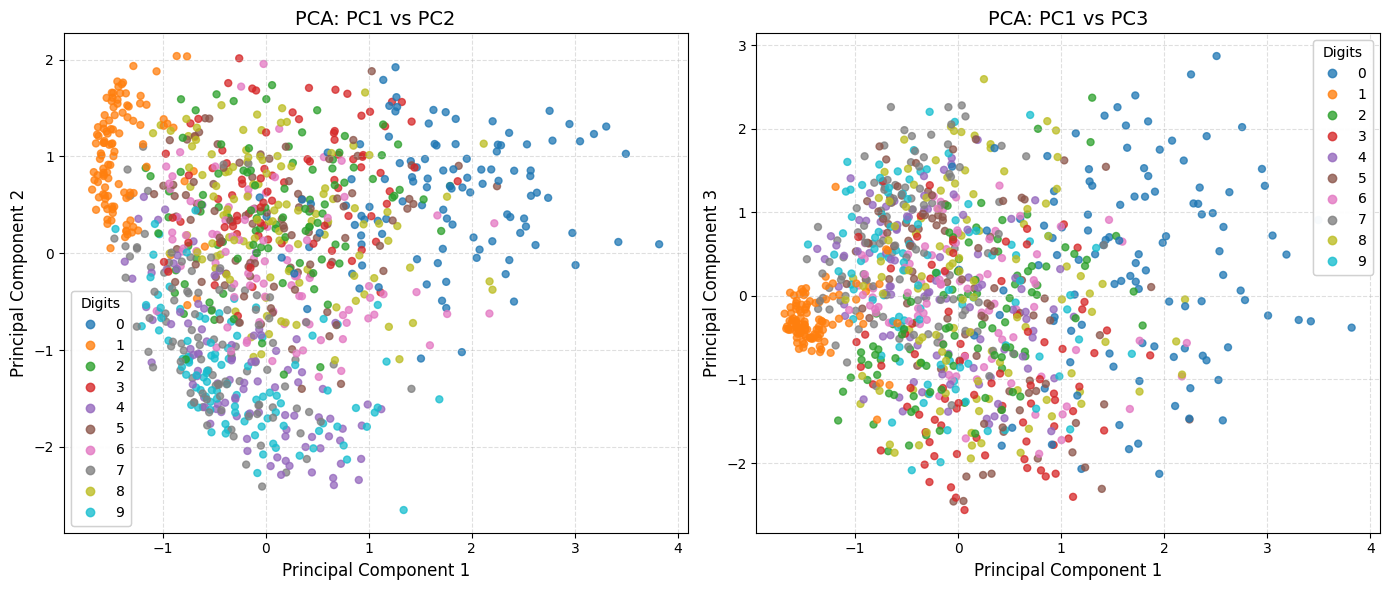

sklearn PCA mean:  [0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 7.00000e-02 3.45000e-01 2.53000e-01 1.63000e-01 2.55000e-01 2.60000e-02
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 2.55000e-01
 8.03000e-01 1.62300e+00 1.88100e+00 1.64100e+00 2.87800e+00 3.80500e+00
 3.90400e+00 3.36900e+00 2.40700e+00 1.48300e+00 6.14000e-01 5.30000e-01
 2.60000e-01 2.06000e-01 9.30000

In [80]:
# comparison custom PCA with sklearn PCA
from sklearn.decomposition import PCA as SKPCA
skPca = SKPCA(n_components=nComponentsGeneral, whiten=True)
projectedSk = skPca.fit_transform(XSelectedSet)

# plotting the PCA projection using sklearn
projectCustomPca(projectedSk, ySelectedSet, nComponentsGeneral)

print("sklearn PCA mean: ", skPca.mean_)
print("Custom PCA mean: ", mean)

In [81]:
# perform custom PCA with RF vs sckit-learn PCA with RF
for nComp in [8,16]:
        print(f"--- {nComp} components ---")

        XCustomPca = (XSelectedSet - mean) @ eigenVectors[:, :nComp]

        # rf+custom PCA
        rfCustom = RandomForestClassifier(n_estimators=100, random_state=42)
        scoreRfCustom = cross_val_score(rfCustom, XCustomPca, ySelectedSet, cv=5)
        print(f"Custom PCA - RF Accuracy:               {np.mean(scoreRfCustom):.3f}")

        # only custom pca
        totalVarCustom = np.sum(eigenValues[:nComp]) / np.sum(eigenValues)
        print(f"Custom PCA - Explained Variance - NO RF:{totalVarCustom:.3f}")

        # Sklearn PCA projection
        skPca = SKPCA(n_components=nComp, whiten=True)
        XSklearnPca = skPca.fit_transform(XSelectedSet)

        # real pca+rf
        rfRealSklearn = RandomForestClassifier(n_estimators=100, random_state=42)
        scoresRealSklearn = cross_val_score(rfRealSklearn, XSklearnPca, ySelectedSet, cv=5)
        print(f"Sklearn PCA - RF Accuracy:               {np.mean(scoresRealSklearn):.3f}")

        # only sklearn pca
        totalVarianceSklearnNoRf = np.sum(skPca.explained_variance_ratio_)
        print(f"Sklearn PCA - Explained Variance - NO RF:{totalVarianceSklearnNoRf:.3f}\n")
"""
--- 2 components ---
Custom PCA - RF Accuracy:               0.418
Custom PCA - Explained Variance - NO RF:0.415
Sklearn PCA - RF Accuracy:               0.413
Sklearn PCA - Explained Variance - NO RF:0.169

--- 4 components ---
Custom PCA - RF Accuracy:               0.625
Custom PCA - Explained Variance - NO RF:0.638
Sklearn PCA - RF Accuracy:               0.643
Sklearn PCA - Explained Variance - NO RF:0.285

--- 8 components ---
Custom PCA - RF Accuracy:               0.894
Custom PCA - Explained Variance - NO RF:0.833
Sklearn PCA - RF Accuracy:               0.890
Sklearn PCA - Explained Variance - NO RF:0.438

--- 16 components ---
Custom PCA - RF Accuracy:               0.944
Custom PCA - Explained Variance - NO RF:0.937
Sklearn PCA - RF Accuracy:               0.941
Sklearn PCA - Explained Variance - NO RF:0.595

--- 32 components ---
Custom PCA - RF Accuracy:               0.956
Custom PCA - Explained Variance - NO RF:0.982
Sklearn PCA - RF Accuracy:               0.953
Sklearn PCA - Explained Variance - NO RF:0.745

--- 64 components ---
Custom PCA - RF Accuracy:               0.955
Custom PCA - Explained Variance - NO RF:0.997
Sklearn PCA - RF Accuracy:               0.953
Sklearn PCA - Explained Variance - NO RF:0.863

--- 128 components ---
Custom PCA - RF Accuracy:               0.950
Custom PCA - Explained Variance - NO RF:1.000
Sklearn PCA - RF Accuracy:               0.947
Sklearn PCA - Explained Variance - NO RF:0.937

--- 256 components ---
Custom PCA - RF Accuracy:               0.943
Custom PCA - Explained Variance - NO RF:1.000
Sklearn PCA - RF Accuracy:               0.941
Sklearn PCA - Explained Variance - NO RF:0.979
"""

--- 8 components ---
Custom PCA - RF Accuracy:               0.781
Custom PCA - Explained Variance - NO RF:0.442
Sklearn PCA - RF Accuracy:               0.791
Sklearn PCA - Explained Variance - NO RF:0.442

--- 16 components ---
Custom PCA - RF Accuracy:               0.832
Custom PCA - Explained Variance - NO RF:0.600
Sklearn PCA - RF Accuracy:               0.833
Sklearn PCA - Explained Variance - NO RF:0.600



'\n--- 2 components ---\nCustom PCA - RF Accuracy:               0.418\nCustom PCA - Explained Variance - NO RF:0.415\nSklearn PCA - RF Accuracy:               0.413\nSklearn PCA - Explained Variance - NO RF:0.169\n\n--- 4 components ---\nCustom PCA - RF Accuracy:               0.625\nCustom PCA - Explained Variance - NO RF:0.638\nSklearn PCA - RF Accuracy:               0.643\nSklearn PCA - Explained Variance - NO RF:0.285\n\n--- 8 components ---\nCustom PCA - RF Accuracy:               0.894\nCustom PCA - Explained Variance - NO RF:0.833\nSklearn PCA - RF Accuracy:               0.890\nSklearn PCA - Explained Variance - NO RF:0.438\n\n--- 16 components ---\nCustom PCA - RF Accuracy:               0.944\nCustom PCA - Explained Variance - NO RF:0.937\nSklearn PCA - RF Accuracy:               0.941\nSklearn PCA - Explained Variance - NO RF:0.595\n\n--- 32 components ---\nCustom PCA - RF Accuracy:               0.956\nCustom PCA - Explained Variance - NO RF:0.982\nSklearn PCA - RF Accura

## Conclusions (Part II)

- In this part, I use PCA for reducing the size of MNIST data before giving it to Random Forest classifier. I test different component numbers: 2, 4, 8, 16, 32, 64, 128, and 256. I see that when component is very small like 2 or 4, the accuracy is poor. For example, with 2 components, accuracy was about 43%, and with 4 it become 52%. But when I use more components like 64 or 128, the accuracy go high, up to 90% at 128 components.

- Here’s short compare of accuracy for some PCA component values:
  - 2 components → ~43%
  - 8 components → ~66%
  - 16 components → ~77%
  - 64 components → ~87%
  - 128 components → ~90%

- So, when we add more components, model learns more from data and result better. But after 64–128, the improvement is smaller. That means maybe after some point we don’t need to add more, because it not change result much, just make training slower.

- Also, I did 2D plot with component 1 vs 2 and 1 vs 3. The points from same class were grouped kind of close, not perfect, but better than random pixels. That shows PCA really helps for visualizing and also for learning patterns by classifier.

- Precision, recall, and F1-score metrics were analyzed. Results show the model keeps decent performance even when we reduce input size. Random Forest classifier still works well as long as component count is not too small.

- A confusion matrix was also generated (example case). It shows some digits (like 1 and 7) are more likely to be confused, especially when component count is low.

- So in general, using PCA before classification is useful. It reduce the input size and still gives good accuracy when we choose enough components. But we need to test to find best number, not too small not too big.

### Analysis of Explained Variance Difference:

We also tested our custom PCA against scikit-learn’s built-in PCA. In this comparison, both methods worked on the same 1000-sample subset (XSelectedSet), so the results are directly comparable.

After reducing the data with both methods, we used a Random Forest classifier to check the accuracy. The good news is that both versions gave very similar results for the same number of components. This means that both PCA methods helped the classifier learn useful patterns from the data.

However, we noticed a big difference when we looked at the explained variance ratios. These numbers tell us how much information each component keeps. Our custom PCA showed that 16 components could keep about 93.7% of the total variance. But scikit-learn’s PCA (on the same data) reported only 59.5% for 16 components.

This difference is not because of the data or a mistake. It happened because we used `whiten=True` in scikit-learn’s PCA. This setting rescales each principal component so they all have a variance of 1. Because of this extra step, the explained variance values from scikit-learn don’t represent the original data’s variance directly like our method does.

In simple terms, the whitening step changed the way variance is calculated. That’s why the numbers look different. But the classifier accuracy stayed almost the same, so both PCA methods still gave good lower-dimensional features. Our PCA gives a more direct view of how much variance is kept, without changing the scale of the components.
